
# COMP 3200 — Week 9: Forms

## Part 1 — Build the Forms - Brady

In this part, we implemented sigmoid, tanh, and ReLU activation functions along with their derivatives, as well as softmax for the output layer. Each activation function changes the input differently, which allows neural networks to learn nonlinear patterns. Their derivatives are used during backpropagation to calculate how the weights should change.


In [1]:

import numpy as np

def sigmoid(x):
  return 1 / (1 + np.exp(-x))

# This function will calculate its derivative without recalculating sigmoid
def sigmoid_deriv(out):
  return out * (1 - out)

def tanh(x):
  return np.tanh(x)

# This will let us calculate its derivative without recalculating tanh
def tanh_deriv(out):
  return 1 - out**2

def relu(x):
  return (x > 0) * x

# This function is ReLU's output tells us whether the input was positive, so we don't need the original input
def relu_deriv(out):
  return (out > 0)

def softmax(z):
  z = z - np.max(z, axis=1, keepdims=True)
  exp_z = np.exp(z)
  return exp_z / np.sum(exp_z, axis=1, keepdims=True)


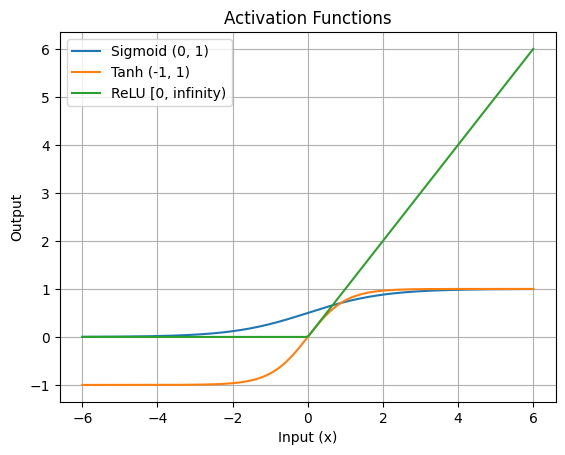

In [2]:

import matplotlib.pyplot as plt

# Create input values from -6 to 6
x = np.linspace(-6, 6, 200)

# calculate each activation function
sigmoid_y = sigmoid(x)
tanh_y = tanh(x)
relu_y = relu(x)

# This will draw all three functions on a single graph
plt.plot(x, sigmoid_y, label="Sigmoid (0, 1)")
plt.plot(x, tanh_y, label="Tanh (-1, 1)")
plt.plot(x, relu_y, label="ReLU [0, infinity)")

# Addings labels
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.title("Activation Functions")
plt.legend()
plt.grid(True)

# code to save the graph
plt.savefig("forms_plot.png")
plt.show()



### Activation Function Comparison

The graph shows how each activation function transforms its inputs. Sigmoid produces values between 0 and 1, while tanh produces values between -1 and 1, allowing for both positive and negative outputs. ReLU sets negative inputs to 0 while keeping positive inputs unchanged. These differences affect how the network learns. Sigmoid and tanh have smaller derivatives toward their extremes, which can slow learning. ReLU maintains a constant derivative of 1 for positive inputs but has a derivative of 0 for negative inputs.


## Part 2 — Prove You Need a Form - Robert

In this part, we demonstrate why nonlinear activation functions are necessary in neural networks. Two linear layers can be combined into a single matrix multiplication without changing the output. However, inserting ReLU between the layers changes the results because negative values are set to zero. This prevents the layers from being collapsed in the same way and allows the network to learn more complex patterns.


In [3]:

import numpy as np

def relu(x):
    return (x > 0) * x

np.random.seed(42) # Callback to previous classes ;)

# Creating weights and initial matrix
X = np.random.randn(5, 4)
W1 = np.random.randn(4, 3)
W2 = np.random.randn(3, 2)

# 2 layer lin output
Y_two = (X @ W1) @ W2

# creating the single collapsed matirx
W_prime = W1 @ W2
Y_one = X @ W_prime

# printing Y_two, and Y_one to show equality using allclose
print("\nnp.allclose(Y_two, Y_one): ")
print(np.allclose(Y_two, Y_one))

# Inserting form and printing it
Y_nl = relu(X @ W1) @ W2
print ("\nY_nl:")
print(Y_nl)
print(" compared to Y_one")
print(Y_one)

# ReLU changes negative intermediate values to 0,
# preventing the same linear matrix collapse.
print("\nNonlinear output matches collapsed output:")
print(np.allclose(Y_nl, Y_one))



np.allclose(Y_two, Y_one): 
True

Y_nl:
[[ 0.51176881 -4.8016891 ]
 [ 0.34657979 -1.22571287]
 [ 0.          0.        ]
 [ 0.48644675 -6.35855427]
 [ 0.46576776 -0.69130525]]
 compared to Y_one
[[-0.0686314  -3.65491772]
 [ 0.37426421  0.9437793 ]
 [-0.17387168  2.02842562]
 [ 0.44439264 -5.96398006]
 [ 0.03270555  3.93458645]]

Nonlinear output matches collapsed output:
False



### Results

The results showed that the two linear layers produced the same output as the single collapsed matrix, with np.allclose() returning True. This happens because matrix multiplication is associative, allowing the two weight matrices to be combined. After inserting ReLU between the layers, the outputs were different. ReLU changes negative intermediate values to zero, introducing a nonlinear transformation that can't generally be represented by a single matrix multiplication. This demonstrates why activation functions are important for building deeper neural networks.


## Part 3 — The Right Form per Layer - Colson

In this part, we upgraded our Week 8 MNIST neural network by using tanh in the hidden layer and softmax in the output layer. We kept dropout and mini-batch training but increased the hidden layer to 100 neurons. The goal was to see how these changes affected the network's ability to recognize handwritten digits. We trained the network for 300 epochs and measured validation accuracy after each epoch.


In [4]:

def train_step(layer_0, Y_batch, W_0_1, W_1_2, mask,
               alpha, hidden_f=tanh, hidden_d=tanh_deriv):
    # forward prop
    layer_1 = hidden_f(layer_0 @ W_0_1)

    # derivative before dropout
    slope = hidden_d(layer_1)

    # Apply dropout
    layer_1 *= mask * 2

    # find output probabilities
    layer_2 = softmax(layer_1 @ W_1_2)

    # find batch size
    batch_size = layer_0.shape[0]

    # find output layer error
    delta_2 = (layer_2 - Y_batch) / batch_size

    # find hidden layer error
    delta_1 = delta_2 @ W_1_2.T * slope

    # apply dropout mask during backprop using exact gradient convention
    delta_1 *= mask * 2

    # update weight matrices
    W_1_2 -= alpha * layer_1.T @ delta_2
    W_0_1 -= alpha * layer_0.T @ delta_1

    return delta_1


In [5]:

from data import load_mnist, one_hot

# load dataset
(X_train, y_train), (X_test, y_test) = load_mnist()

# Split training and validation data
X_val = X_train[1000:2000]
Y_val = one_hot(y_train[1000:2000])

X_train = X_train[:1000]
Y_train = one_hot(y_train[:1000])

# Prepare test labels
Y_test = one_hot(y_test)


np.random.seed(1)

alpha = 0.02
epochs = 300
hidden_size = 100
batch_size = 100

W_0_1 = 0.02 * np.random.random((784, hidden_size)) - 0.01
W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1


In [6]:

val_accuracies = []

# training time
for epoch in range(epochs):

    # process the training images in batches
    for s in range(0, len(X_train), batch_size):

        # current batch
        layer_0 = X_train[s:s + batch_size]
        Y_batch = Y_train[s:s + batch_size]

        # new dropout mask
        mask = np.random.randint(2, size=(len(layer_0), hidden_size))

        # Train on current batch
        train_step(layer_0, Y_batch, W_0_1, W_1_2, mask, alpha)

    # validation accuracy without dropout
    val_hidden = tanh(X_val @ W_0_1)
    val_scores = val_hidden @ W_1_2

    # find predicted and actual digits
    val_predictions = np.argmax(val_scores, axis=1)
    val_actual = np.argmax(Y_val, axis=1)

    # get accuracy
    val_accuracy = np.mean(val_predictions == val_actual) * 100

    # store accuracy for plotting
    val_accuracies.append(val_accuracy)

    # show the progress
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Validation Accuracy: {val_accuracy:.2f}%")


Epoch 50/300, Validation Accuracy: 83.70%
Epoch 100/300, Validation Accuracy: 86.90%
Epoch 150/300, Validation Accuracy: 87.30%
Epoch 200/300, Validation Accuracy: 87.60%
Epoch 250/300, Validation Accuracy: 87.90%
Epoch 300/300, Validation Accuracy: 87.70%


In [7]:

# final test evaluation without dropout
test_hidden = tanh(X_test @ W_0_1)
test_scores = test_hidden @ W_1_2

# get preds and actual digits
test_predictions = np.argmax(test_scores, axis=1)
test_actual = np.argmax(Y_test, axis=1)

# final test accuracy
test_accuracy = np.mean(test_predictions == test_actual) * 100

print(f"Final Test Accuracy: {test_accuracy:.2f}%")


Final Test Accuracy: 86.66%


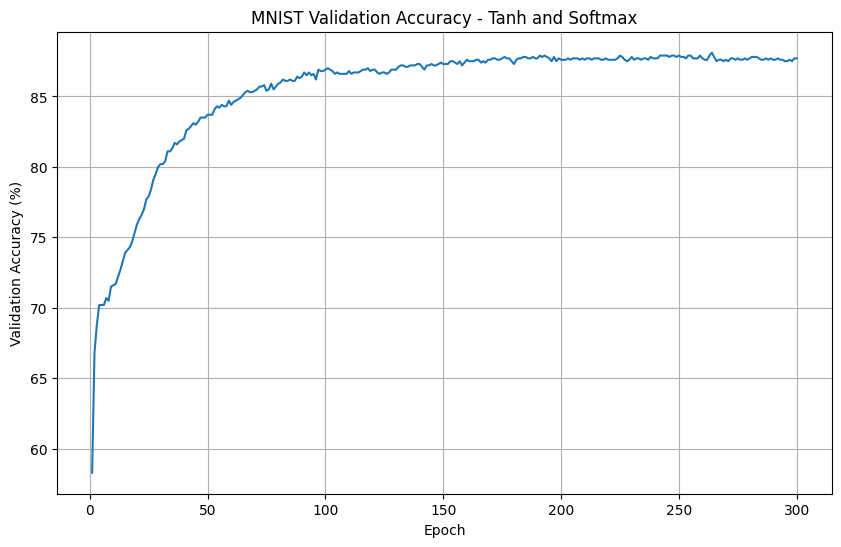

In [8]:

# plot

plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), val_accuracies)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("MNIST Validation Accuracy - Tanh and Softmax")

plt.grid(True)
plt.savefig("upgrade_plot.png")
plt.show()



### Results and Comparison to Week 8

Our updated network reached a final validation accuracy of 87.70% and a test accuracy of 86.66%. The validation accuracy generally increased throughout training, showing that the network was learning to recognize handwritten digits. Compared to our Week 8 batched network, which finished with 84.20% validation accuracy, our Week 9 network improved by 3.50 percentage points. However, this improvement cannot be attributed entirely to the activation functions because we also increased the hidden layer from 40 to 100 neurons. Part 4 will help us compare the activation functions more fairly by keeping the other network settings the same.



## Part 4 — Compare the Forms - Kevin

In this part, we compare the performance of three different hidden-layer activation functions: tanh, ReLU, and sigmoid. Each network uses the same architecture, learning rate, training data, and dropout settings so that we can compare the activation functions fairly. We train each network for 300 epochs and compare their final validation accuracies.


In [9]:

# load dataset
(X_train, y_train), (X_test, y_test) = load_mnist()

# split training and validation data
X_val = X_train[1000:2000]
Y_val = one_hot(y_train[1000:2000])

X_train = X_train[:1000]
Y_train = one_hot(y_train[:1000])

alpha = 0.02
epochs = 300
hidden_size = 100
batch_size = 100

# forms to test
forms = [
    ("tanh", tanh, tanh_deriv),
    ("relu", relu, relu_deriv),
    ("sigmoid", sigmoid, sigmoid_deriv)
]

results = {}


In [10]:

# train network for each activation form
for name, hidden_f, hidden_d in forms:
    print(f"Training network with {name}...")

    np.random.seed(1)

    W_0_1 = 0.02 * np.random.random((784, hidden_size)) - 0.01
    W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

    for epoch in range(epochs):

        # process the training images in batches
        for s in range(0, len(X_train), batch_size):
            layer_0 = X_train[s:s + batch_size]
            Y_batch = Y_train[s:s + batch_size]

            # new dropout mask
            mask = np.random.randint(2, size=(len(layer_0), hidden_size))

            # train on current batch
            train_step(layer_0, Y_batch, W_0_1, W_1_2, mask, alpha, hidden_f, hidden_d)

    # validation accuracy without dropout
    val_hidden = hidden_f(X_val @ W_0_1)
    val_scores = val_hidden @ W_1_2

    # find predicted and actual digits
    val_predictions = np.argmax(val_scores, axis=1)
    val_actual = np.argmax(Y_val, axis=1)

    # get accuracy
    val_accuracy = np.mean(val_predictions == val_actual) * 100
    results[name] = val_accuracy

    print(f"Final Validation Accuracy ({name}): {val_accuracy:.2f}%\n")

# print table
print("=" * 30)
print(f"{'Form':<10} | {'Val Accuracy':<15}")
print("-" * 30)
for name, acc in results.items():
    print(f"{name:<10} | {acc:.2f}%")
print("=" * 30)


Training network with tanh...
Final Validation Accuracy (tanh): 87.70%

Training network with relu...
Final Validation Accuracy (relu): 88.70%

Training network with sigmoid...
Final Validation Accuracy (sigmoid): 82.60%

Form       | Val Accuracy   
------------------------------
tanh       | 87.70%
relu       | 88.70%
sigmoid    | 82.60%


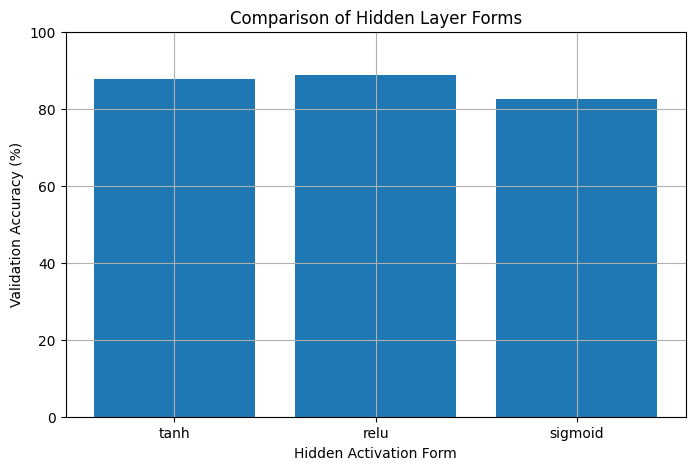

In [11]:

# plot comparison
names = list(results.keys())
accuracies = list(results.values())

plt.figure(figsize=(8, 5))
plt.bar(names, accuracies)

plt.xlabel("Hidden Activation Form")
plt.ylabel("Validation Accuracy (%)")
plt.title("Comparison of Hidden Layer Forms")
plt.ylim(0, 100)

plt.grid(True)
plt.savefig("compare_plot.png")
plt.show()



### Results and Comparison

| Hidden Activation | Final Validation Accuracy |
|---|---|
| Tanh | 87.7% |
| ReLU | 88.7% |
| Sigmoid | 82.6% |

The results show that the choice of hidden-layer activation function affects the network's performance, even when the architecture, learning rate, and training data remain the same. Tanh allows both positive and negative outputs, while ReLU zeros out negative inputs and keeps positive inputs unchanged. Sigmoid compresses its outputs between 0 and 1 and has a smaller maximum derivative, which can lead to smaller gradients and slower learning at the same learning rate. This demonstrates why choosing an appropriate activation function matters rather than using the same one for every network.



## Part 5 — Tests - Elijah

In this part, we test the activation functions, derivatives, linear layer behavior, and backpropagation implementation. We also verify that softmax produces valid probabilities and that tanh performs better than sigmoid at the same learning rate.

These tests help ensure that the functions are working correctly and that the network's training behavior matches the assignment requirements.


In [12]:

%run test_forms.py


 PASS: test_backprop
 PASS: test_derivs
 PASS: test_lin_collapse
 PASS: test_ranges
 PASS: test_relu
Training network with tanh...
Final Validation Accuracy (tanh): 73.90%

Training network with sigmoid...
Final Validation Accuracy (sigmoid): 20.70%

 PASS: test_right_form
 PASS: test_softmax
PASS: test_backprop
PASS: test_derivs
PASS: test_lin_collapse
PASS: test_ranges
PASS: test_relu
PASS: test_right_form
PASS: test_softmax


## Part 6 - Elijah

In part 4, with the same overall network structures and data, with only a change in hidden layer form, 
we got 3 distinct values for the three different forms. This is because the different forms each have 
unique capabilities in their own rights. Tanh compresses outputs between -1 and 1 allowing for the model 
to still see negative correlations between values and greater slopes around 0, sigmoid compresses outputs 
between 0 and 1, and relu just 0s any negative output allowing a slope always = 1 or 0. Tanh is strong 
and balanced with the capability of negative values so the model can see negative numbers while relu is 
aggressive and allows the model to train quickly. Sigmoid is weaker but still can provide the model a 
different perspective of the datapoint, albeit a slower training time. The Verach, just like a naïve 
neural network creator, have never given their model the chance to view the situation with a different 
perspective that could provide very valuable insights for the model. Without considering other forms, 
you are potentially denying yourself the best view of the data where your model picks 
out the best combination of factors for the situation.